# Customer Churn - Exploratory Data Analysis

This notebook explores the **synthetic** customer churn dataset used by the project
(`data/customer_churn.csv`). Every customer is fictional - there is no real personal data.

**Goals**
1. Understand the raw data and its quality problems.
2. Clean it with the same code the model uses (`src/data_processing.py`).
3. Explore how churn relates to contract, tenure, charges, payment, services and segments.
4. Summarise observations that motivate the feature engineering and modelling.

> ⚠️ **Correlation is not causation.** The patterns below show *associations* in the data.
> A group with a higher churn rate does not prove that the attribute *causes* churn.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import DATA_PATH, NUMERIC_COLUMNS
from src.data_processing import load_raw_data, clean_data
from src.feature_engineering import engineer_features
from src.insights import churn_rate_by, highest_churn_segment
from src import plots

pd.set_option("display.max_columns", 30)
%matplotlib inline

## 1. Raw data and data-quality check

In [2]:
raw = load_raw_data(DATA_PATH)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
raw.head()

7,042 rows x 25 columns


,customer_id,signup_date,gender,age,partner,dependents,region,tenure_months,contract_type,payment_method,paperless_billing,internet_service,phone_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,monthly_charges,total_charges,support_tickets,satisfaction_score,late_payments,churn
0,CUST-01742,2023-11-22,Male,66,No,No,South,25,Two year,Credit card,No,No,Yes,No,No,No,No,No,No,18.0,459.15,0,NaN,0,No
1,CUST-00458,2023-07-11,Female,31,No,No,South,30,Two year,Bank transfer,No,DSL,Yes,No,No,No,No,Yes,Yes,62.56,1818.95,6,2,1,No
2,CUST-00178,2025-02-21,Female,46,No,No,North,10,One year,Electronic check,No,DSL,Yes,No,Yes,No,Yes,Yes,Yes,74.17,732.44,1,4,0,No
3,CUST-04883,2024-12-17,Female,35,No,No,West,12,One year,Mailed check,No,No,Yes,No,No,No,No,No,No,21.89,269.26,1,4,1,No
4,CUST-03613,2025-09-29,Male,35,Yes,No,South,3,Month-to-month,Credit card,Yes,Fiber optic,Yes,No,No,Yes,No,No,Yes,85.77,272.14,2,2,0,Yes


In [3]:
quality = pd.DataFrame({
    "missing": raw.isna().sum(),
    "blank_strings": (raw.apply(lambda s: s.astype(str).str.strip() == "")).sum(),
    "unique_values": raw.nunique(),
})
print("Exact duplicate rows:", raw.duplicated().sum())
quality[(quality.missing > 0) | (quality.blank_strings > 0)]

Exact duplicate rows: 42


,missing,blank_strings,unique_values
age,105,0,72
payment_method,70,0,6
internet_service,35,0,6
monthly_charges,71,0,4085
total_charges,21,8,6889
support_tickets,70,0,11
satisfaction_score,141,0,6
churn,14,0,2


In [4]:
# Inconsistent category spellings in the raw data
for col in ["contract_type", "internet_service", "gender", "partner"]:
    print(col, "->", sorted(raw[col].dropna().unique()))

contract_type -> ['MTM', 'Month to Month', 'Month-to-month', 'One year', 'Two year', 'month-to-month']
internet_service -> ['DSL', 'Fiber Optic ', 'Fiber optic', 'Fibre', 'No', 'fiber optic']
gender -> ['F', 'Female', 'M', 'Male', 'female', 'male']
partner -> ['N', 'No', 'Y', 'Yes', 'no', 'yes']


**Observations**
- A few percent of values are missing in several columns, and some `total_charges` are blank strings.
- The same category is written in several ways (e.g. `MTM`, `month-to-month`, `Month to Month`).
- There are exact duplicate rows and a handful of impossible numbers (e.g. negative charges, age 999).

## 2. Cleaning

The cleaning rules are documented in `src/data_processing.py` and the README. Invalid values are
set to *missing* rather than deleting whole customers; the model pipeline later imputes them using
statistics learned from the **training split only** (no data leakage).

In [5]:
df, report = clean_data(raw)
pd.DataFrame(report.as_rows(), columns=["Step", "Count"])

,Step,Count
0,Rows loaded,"7,042"
1,Exact duplicate rows removed,42
2,Repeated customer IDs removed (first kept),0
3,Rows with unknown churn label removed,14
4,Blank total_charges set to 0 (tenure = 0),8
5,Unparseable signup dates set to missing,14
6,Category spellings standardised: gender,209
7,Category spellings standardised: partner,209
8,Category spellings standardised: contract_type,114
9,Category spellings standardised: payment_method,69


In [6]:
print("Remaining missing values (imputed later inside the pipeline):")
pd.Series(report.missing_after_cleaning, name="missing").to_frame()

Remaining missing values (imputed later inside the pipeline):


,missing
signup_date,14
age,119
payment_method,70
internet_service,35
monthly_charges,84
total_charges,21
support_tickets,70
satisfaction_score,147


## 3. Churn distribution

Churn rate: 24.9%


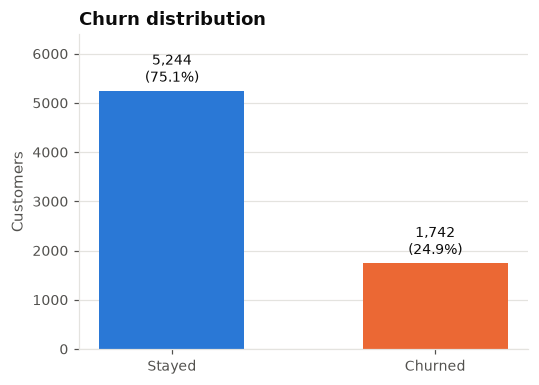

In [7]:
print(f"Churn rate: {df.churn.mean():.1%}")
plots.churn_distribution(df);

About one in four customers churned. The classes are **imbalanced**, so accuracy alone would be
misleading: predicting "stays" for everybody would already be ~75% accurate while catching no churners.
Model evaluation therefore focuses on precision, recall, F1 and ROC-AUC.

## 4. Churn by contract type

,contract_type,customers,churned,churn_rate
0,Month-to-month,3801,1495,0.393318
1,One year,1693,183,0.108092
2,Two year,1492,64,0.042895


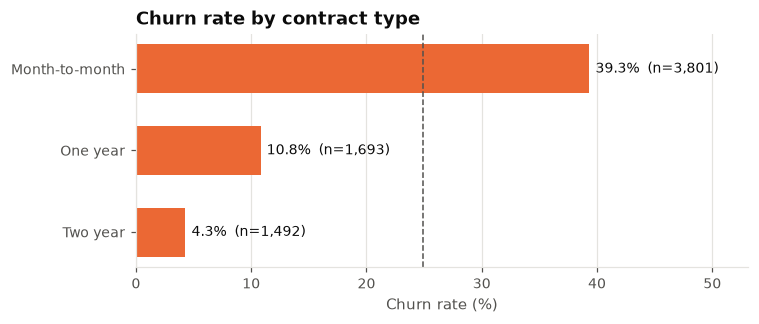

In [8]:
rates = churn_rate_by(df, "contract_type")
display(rates)
plots.churn_rate_bar(rates, "contract_type", "Churn rate by contract type", overall=df.churn.mean());

## 5. Churn by tenure

,tenure_group,customers,churned,churn_rate
0,0-12 months,2178,927,0.425620
1,13-24 months,1985,570,0.287154
2,25-48 months,1713,215,0.125511
3,49+ months,1110,30,0.027027


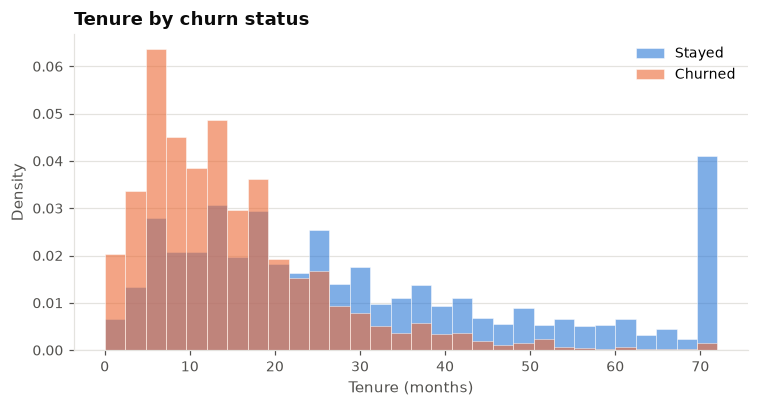

In [9]:
eng = engineer_features(df)
display(churn_rate_by(eng, "tenure_group"))
plots.histogram_by_churn(df, "tenure_months", title="Tenure by churn status", xlabel="Tenure (months)");

## 6. Churn by monthly charges

,charge_band,customers,churned,churn_rate
0,$85+,1111,403,0.362736
1,$60-85,3120,931,0.298397
2,$35-60,1133,196,0.172992
3,< $35,1538,187,0.121586


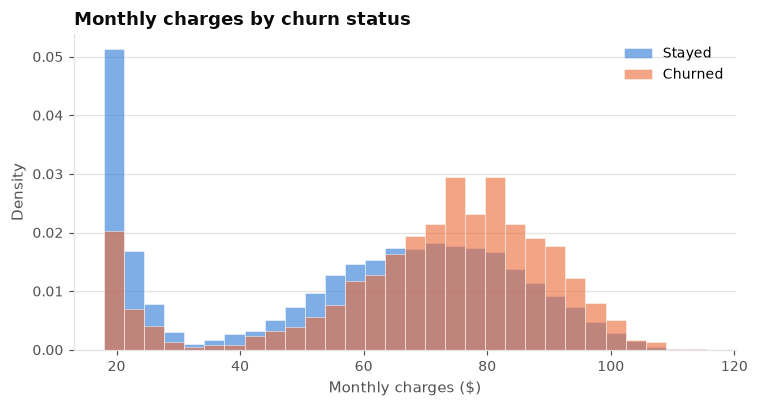

In [10]:
eng["charge_band"] = pd.cut(eng.monthly_charges, [0, 35, 60, 85, 200],
                           labels=["< $35", "$35-60", "$60-85", "$85+"])
display(churn_rate_by(eng, "charge_band"))
plots.histogram_by_churn(df, "monthly_charges", title="Monthly charges by churn status",
                         xlabel="Monthly charges ($)");

## 7. Churn by payment method

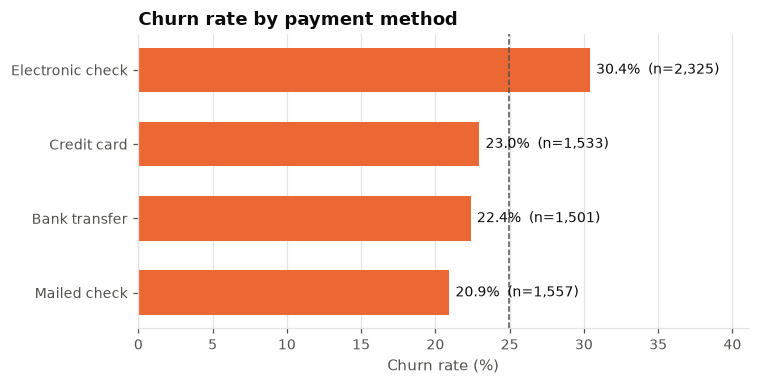

In [11]:
rates = churn_rate_by(df, "payment_method")
plots.churn_rate_bar(rates, "payment_method", "Churn rate by payment method", overall=df.churn.mean());

## 8. Churn by service type

,internet_service,customers,churned,churn_rate
0,Fiber optic,3060,1134,0.370588
1,DSL,2405,422,0.175468
2,No,1486,178,0.119785


,tech_support,customers,churned,churn_rate
0,No,5030,1282,0.254871
1,Yes,1956,460,0.235174


,online_security,customers,churned,churn_rate
0,No,5072,1288,0.253943
1,Yes,1914,454,0.237200


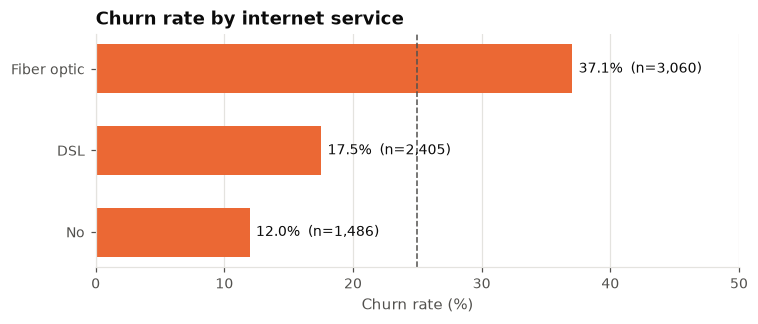

In [12]:
for col in ["internet_service", "tech_support", "online_security"]:
    display(churn_rate_by(df, col))
plots.churn_rate_bar(churn_rate_by(df, "internet_service"), "internet_service",
                     "Churn rate by internet service", overall=df.churn.mean());

In [13]:
display(churn_rate_by(eng, "service_count"))

,service_count,customers,churned,churn_rate
0,3.0,970,292,0.301031
1,4.0,1608,474,0.294776
2,5.0,1513,424,0.280238
3,2.0,254,71,0.279528
4,6.0,852,225,0.264085
5,7.0,247,61,0.246964
6,1.0,1370,172,0.125547
7,0.0,144,14,0.097222


## 9. Churn by customer segment

In [14]:
for col in ["age_group", "region", "partner", "dependents"]:
    display(churn_rate_by(eng, col))
seg = highest_churn_segment(df)
print("Highest-churn two-attribute segment:", seg)

,age_group,customers,churned,churn_rate
0,60+,1027,285,0.277507
1,18-29,1172,297,0.253413
2,45-59,2286,565,0.247157
3,30-44,2382,558,0.234257


,region,customers,churned,churn_rate
0,West,1518,404,0.266140
1,South,1688,422,0.250000
2,North,1923,479,0.249090
3,East,1857,437,0.235326


,partner,customers,churned,churn_rate
0,No,3670,976,0.265940
1,Yes,3316,766,0.231001


,dependents,customers,churned,churn_rate
0,Yes,1886,480,0.254507
1,No,5100,1262,0.247451


Highest-churn two-attribute segment: {'segment': 'Tenure group = 0-12 months & Internet service = Fiber optic', 'customers': 977, 'churn_rate': 0.5834186284544524}


## 10. Support and satisfaction

In [15]:
display(churn_rate_by(df, "satisfaction_score"))
eng["tickets_band"] = pd.cut(eng.support_tickets, [-1, 0, 2, 4, 50], labels=["0", "1-2", "3-4", "5+"])
display(churn_rate_by(eng, "tickets_band"))

,satisfaction_score,customers,churned,churn_rate
0,1.0,217,114,0.525346
1,2.0,1189,438,0.368377
2,3.0,2614,689,0.263581
3,4.0,2163,396,0.183079
4,5.0,656,64,0.097561


,tickets_band,customers,churned,churn_rate
0,5+,408,215,0.526961
1,3-4,1484,546,0.367925
2,1-2,3452,775,0.224508
3,0,1572,186,0.118321


## 11. Signup date

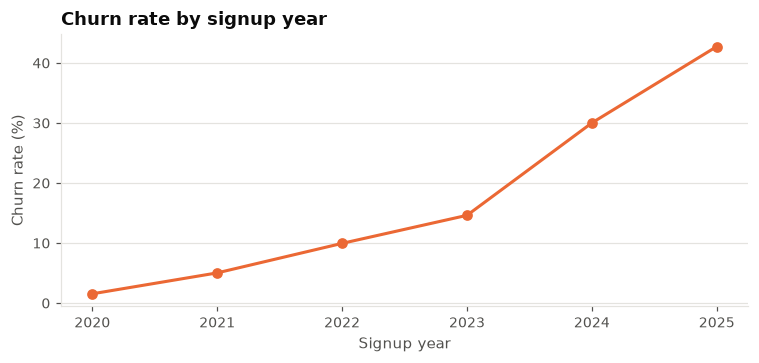

In [16]:
plots.signup_trend(df);

Customers who signed up recently churn more - but recent sign-ups also have short tenure, so this
largely repeats the tenure pattern. `signup_date` is therefore kept for analysis but **not** used as a
model feature (it would duplicate tenure and ties the model to a specific snapshot date).

## 12. Correlations (numeric features)

tenure_months        -0.326393
total_charges        -0.213008
satisfaction_score   -0.211675
age                   0.016336
late_payments         0.085151
service_count         0.109691
avg_monthly_spend     0.207173
monthly_charges       0.208487
support_tickets       0.267968
Name: churn, dtype: float64

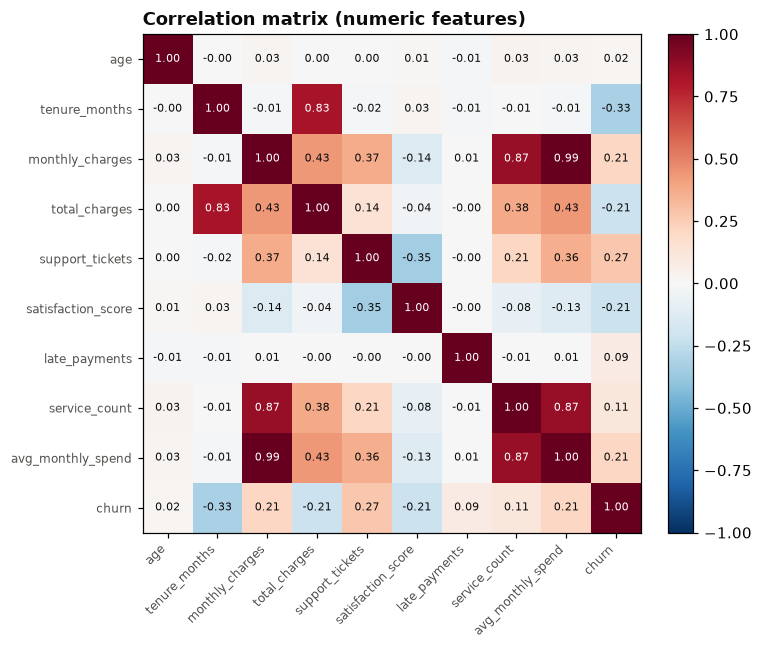

In [17]:
cols = NUMERIC_COLUMNS + ["service_count", "avg_monthly_spend", "churn"]
display(eng[cols].corr()["churn"].drop("churn").sort_values())
plots.correlation_heatmap(eng, cols);

`monthly_charges`, `service_count` and `avg_monthly_spend` are strongly correlated with each other
(more services -> higher bill), and `total_charges` is driven by tenure. Correlated inputs make individual
Logistic Regression coefficients harder to interpret, which is one reason the project also uses
SHAP and permutation importance.

## 13. Key observations (associations, not causes)

- **Contract type** shows the largest difference: month-to-month customers churn far more than
  customers on one- or two-year contracts.
- **Tenure**: churn is concentrated in the first year and falls steadily with tenure.
- **Monthly charges**: churners tend to have higher monthly bills.
- **Payment method**: electronic-check customers churn more than automatic-payment customers.
- **Services**: fiber-optic customers churn more; customers with tech support / online security churn less.
- **Support experience**: more support tickets and lower satisfaction scores go with higher churn.
- Demographics (gender, region) show small differences.

These observations motivated the engineered features (tenure groups, service count, average spend,
new-customer flag, protection bundle) and the business recommendations in the dashboard. Whether any
of these factors *causes* churn would need a controlled experiment (e.g. an A/B test of a retention offer).